# K-Means and Hierarchical Clustering on Sales Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]
X_scaled = StandardScaler().fit_transform(X)

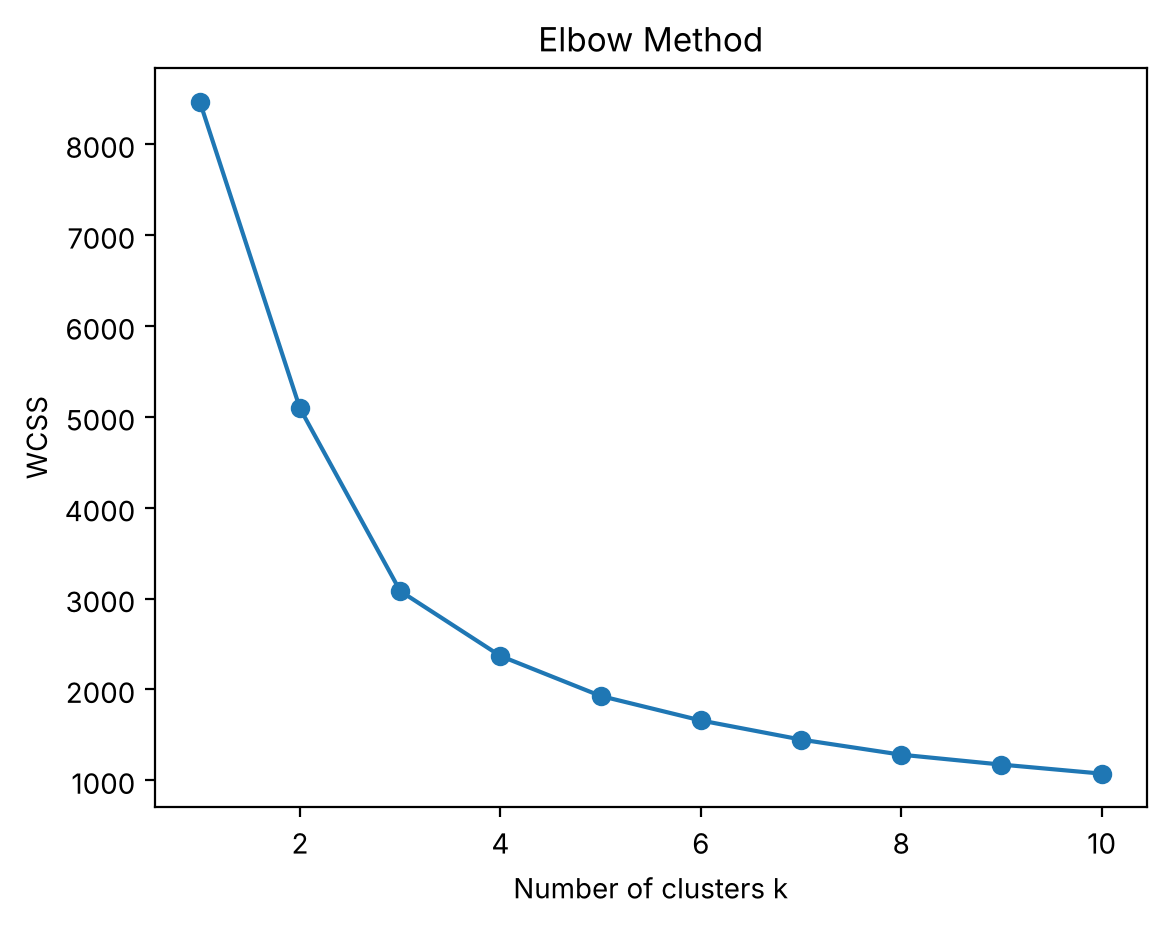

In [3]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [4]:
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
df["KMeans_Cluster"] = km.fit_predict(X_scaled)
print(df["KMeans_Cluster"].value_counts())
print(df.groupby("KMeans_Cluster")[["QUANTITYORDERED", "PRICEEACH", "SALES"]].mean())

KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64
                QUANTITYORDERED  PRICEEACH        SALES
KMeans_Cluster                                         
0                     35.125993  57.130216  2009.829955
1                     43.847850  96.637795  5584.007299
2                     27.392271  94.865575  3089.153662


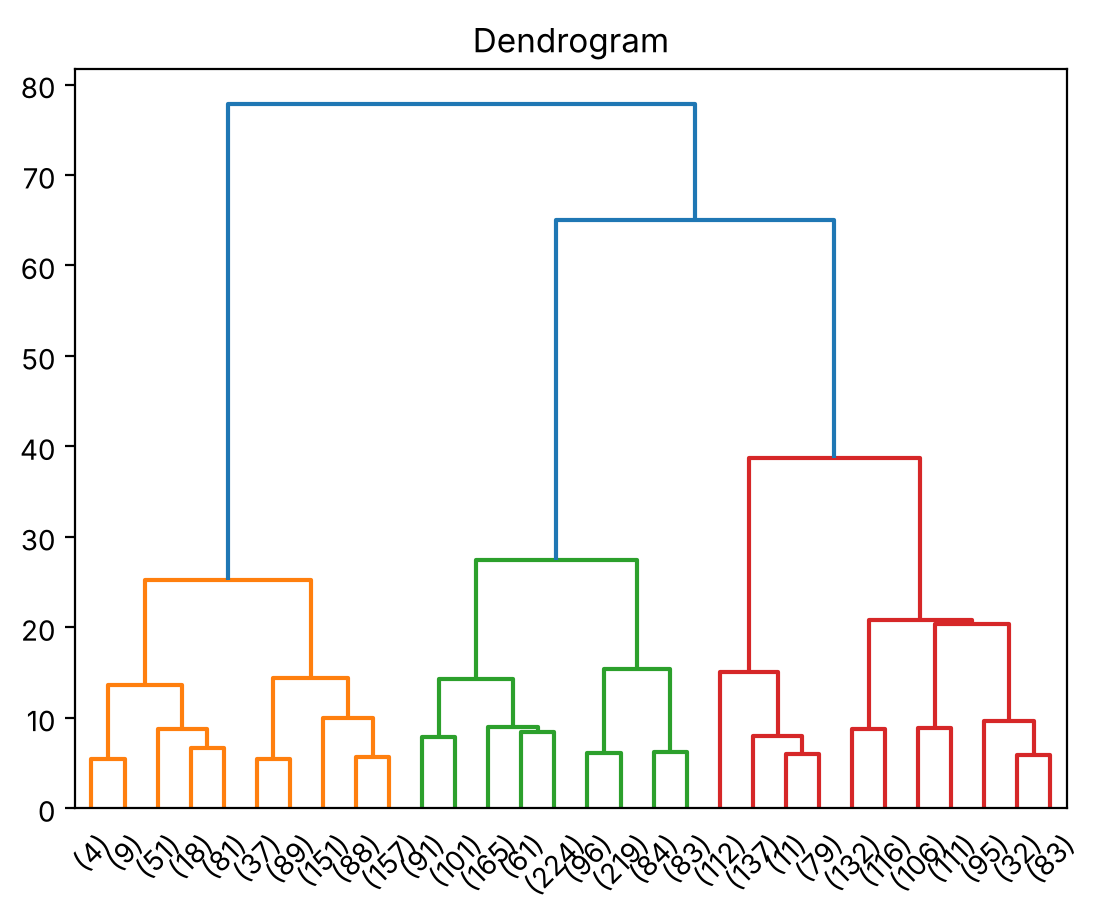

Hier_Cluster
2    1124
3    1014
1     685
Name: count, dtype: int64


In [5]:
Z = linkage(X_scaled, method="ward")
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Dendrogram")
plt.show()
df["Hier_Cluster"] = fcluster(Z, k, criterion="maxclust")
print(df["Hier_Cluster"].value_counts())